# Training K-Means — Segmen Destinasi TravelFit (443 Destinasi)

Notebook ini melatih K-Means dari fitur hasil preprocessing, lalu menampilkan seluruh proses: pemilihan k, perhitungan silhouette, isi segmen, dan metrik evaluasi.

- **Masukan:** `data/processed/destinations_kmeans_features_java443.csv` (keluaran notebook 03 atau `manage.py preprocess_destinations`).
- **Tidak menulis apa pun.** Label website dan laporan JSON hanya diperbarui oleh `manage.py train_clusters`. Kode K-Means di sini sama dengan command tersebut, dan bagian 8 membandingkan hasilnya dengan laporan tersimpan.
- **K-Means bukan metode peringkat.** Label segmen tidak menyaring kandidat dan tidak mengubah skor TOPSIS.

## Langkah
1. Setup dan muat fitur
2. Algoritma K-Means dan silhouette
3. Latih k = 2 sampai 6 dan pilih k
4. Perhitungan silhouette
5. Isi tiap segmen
6. Metrik tambahan
7. Interpretasi hasil
8. Bandingkan dengan laporan tersimpan

In [1]:
from pathlib import Path
import json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_URL = 'https://github.com/ReBioNC/SPK_Destinasi_Wisata.git'
MARKER = 'data/processed/destinations_kmeans_features_java443.csv'

# Cari folder project: folder kerja dan folder di atasnya (lokal), hasil clone atau Drive (Colab).
# Jika dibuka di Colab tanpa data, repository di-clone otomatis.
# Jika tetap tidak ketemu, isi manual, contoh: PROJECT_ROOT = Path('C:/Users/ASUS/Documents/SPK_Destinasi_Wisata')
if 'PROJECT_ROOT' not in globals():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents, here / 'SPK_Destinasi_Wisata',
                  Path('/content/SPK_Destinasi_Wisata'), Path('/content/drive/MyDrive/TravelFit')]
    PROJECT_ROOT = next((c for c in candidates if (c / MARKER).is_file()), None)
    if PROJECT_ROOT is None:
        try:
            import google.colab  # noqa: F401
        except ImportError:
            raise FileNotFoundError(f'Folder project tidak ditemukan dari {here}. '
                                    'Buka folder SPK_Destinasi_Wisata atau isi PROJECT_ROOT manual.')
        subprocess.run(['git', 'clone', '-q', REPO_URL, '/content/SPK_Destinasi_Wisata'], check=True)
        PROJECT_ROOT = Path('/content/SPK_Destinasi_Wisata')
PROJECT_ROOT = Path(PROJECT_ROOT)

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False, 'axes.edgecolor': '#9fb0a8',
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e4e9e5', 'grid.linewidth': 1,
    'text.color': '#183b36', 'axes.labelcolor': '#52635e', 'xtick.color': '#52635e', 'ytick.color': '#52635e',
    'axes.titlecolor': '#183b36', 'legend.frameon': False,
})
SERIES = ['#0f8f7c', '#c9581a']

FEATURES_PATH = 'data/processed/destinations_kmeans_features_java443.csv'
DESTINATIONS_PATH = 'data/processed/destinations_clean_java443.csv'
REPORT_PATH = 'reports/clustering/kmeans_evaluation.json'
print('PROJECT_ROOT:', PROJECT_ROOT)
print('numpy', np.__version__, '| pandas', pd.__version__)

PROJECT_ROOT: <folder project>
numpy 2.4.6 | pandas 3.0.6


## 1. Muat fitur
Setiap destinasi memiliki 8 fitur: harga tiket dan rating yang sudah distandardisasi, ditambah 6 kolom one-hot kategori. Indikator fasilitas (C4), koordinat, dan provinsi tidak dipakai.

In [2]:
features = pd.read_csv(PROJECT_ROOT / FEATURES_PATH)
destinations = pd.read_csv(PROJECT_ROOT / DESTINATIONS_PATH)
assert len(features) == 443 and set(features['place_id']) == set(range(1, 444))
assert features['place_id'].tolist() == destinations['place_id'].tolist()
feature_columns = [c for c in features.columns if c != 'place_id']
X = features[feature_columns].to_numpy(dtype=float)
assert np.isfinite(X).all()
print('Data latih:', X.shape[0], 'destinasi x', X.shape[1], 'fitur')
display(features.head())
display(features[feature_columns].describe().round(3))

Data latih: 443 destinasi x 8 fitur


,place_id,c1_ticket_price_z,c2_rating_z,category_alam,category_bahari,category_belanja,category_budaya,category_hiburan,category_religi
0,1,-0.046412,0.756541,0.0,0.0,0.0,1.0,0.0,0.0
1,2,-0.470773,0.756541,0.0,0.0,0.0,1.0,0.0,0.0
2,3,5.258108,0.756541,0.0,0.0,0.0,0.0,1.0,0.0
3,4,-0.258592,0.275007,0.0,0.0,0.0,0.0,1.0,0.0
4,5,1.523726,0.275007,0.0,0.0,0.0,0.0,1.0,0.0


,c1_ticket_price_z,c2_rating_z,category_alam,category_bahari,category_belanja,category_budaya,category_hiburan,category_religi
count,443.000,443.000,443.000,443.000,443.000,443.000,443.000,443.000
mean,-0.000,-0.000,0.244,0.108,0.034,0.269,0.307,0.038
std,1.001,1.001,0.430,0.311,0.181,0.444,0.462,0.192
min,-0.471,-5.022,0.000,0.000,0.000,0.000,0.000,0.000
25%,-0.471,-0.688,0.000,0.000,0.000,0.000,0.000,0.000
50%,-0.365,0.275,0.000,0.000,0.000,0.000,0.000,0.000
75%,-0.046,0.757,0.000,0.000,0.000,1.000,1.000,0.000
max,5.381,2.683,1.000,1.000,1.000,1.000,1.000,1.000


## 2. Algoritma
**K-Means** mengelompokkan data dengan meminimalkan inertia, yaitu jumlah kuadrat jarak setiap titik ke pusat clusternya:

$$\text{inertia} = \sum_{j=1}^{k}\sum_{x_i \in C_j}\lVert x_i - c_j \rVert^2$$

Langkah `fit_kmeans`:
1. **Inisialisasi k-means++:** pusat pertama diambil acak, pusat berikutnya diberi peluang sebanding dengan kuadrat jaraknya ke pusat terdekat.
2. **Tetapkan cluster:** setiap titik masuk ke pusat terdekat.
3. **Perbarui pusat:** pusat baru adalah rata-rata anggota. Langkah 2 dan 3 diulang sampai perubahan kurang dari $10^{-6}$ atau mencapai 100 iterasi.
4. **Ulangi 10 kali** dengan seed 42, lalu simpan hasil dengan inertia terkecil.

**Silhouette** membandingkan kerapatan di dalam cluster dengan keterpisahan dari cluster lain:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

- $a(i)$: rata-rata jarak destinasi $i$ ke anggota lain di clusternya.
- $b(i)$: rata-rata jarak destinasi $i$ ke anggota cluster lain yang terdekat.
- $s(i)$ bernilai $-1$ sampai $1$. Mendekati 1 berarti tepat, mendekati 0 berarti di perbatasan, dan negatif berarti lebih dekat ke cluster lain.

In [3]:
def fit_kmeans(data, k, seed=42, starts=10, max_iter=100):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(starts):
        centers = [data[rng.integers(len(data))]]
        for _ in range(1, k):
            d2 = np.min(((data[:, None, :] - np.array(centers)[None, :, :]) ** 2).sum(axis=2), axis=1)
            p = d2 / d2.sum() if d2.sum() else None
            centers.append(data[rng.choice(len(data), p=p)])
        centers = np.array(centers)
        for _ in range(max_iter):
            d2 = ((data[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
            labels = d2.argmin(axis=1)
            updated = np.array([
                data[labels == j].mean(axis=0) if np.any(labels == j)
                else data[np.argmax(d2.min(axis=1))]
                for j in range(k)
            ])
            if np.allclose(centers, updated, rtol=0, atol=1e-6):
                break
            centers = updated
        d2 = ((data[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = d2.argmin(axis=1)
        inertia = float(d2[np.arange(len(data)), labels].sum())
        if best is None or inertia < best[0]:
            best = (inertia, centers, labels)
    return best


def silhouette_samples(data, labels):
    labels = np.asarray(labels)
    norms = (data ** 2).sum(axis=1)
    distances = np.sqrt(np.maximum(norms[:, None] + norms[None, :] - 2 * data @ data.T, 0))
    a, b, s = np.zeros(len(data)), np.zeros(len(data)), np.zeros(len(data))
    for i, own in enumerate(labels):
        same = labels == own
        if same.sum() == 1:
            continue
        a[i] = distances[i, same].sum() / (same.sum() - 1)
        b[i] = min(distances[i, labels == other].mean() for other in set(labels.tolist()) if other != own)
        s[i] = (b[i] - a[i]) / max(a[i], b[i]) if max(a[i], b[i]) else 0.0
    return a, b, s, distances

## 3. Latih k = 2 sampai 6 dan pilih k
Aturan pemilihan: ambil **silhouette tertinggi** di antara k yang cluster terkecilnya minimal 5% data (22 anggota). Bila seri, pilih k yang lebih kecil. Inertia selalu turun ketika k naik, sehingga tidak dipakai sendiri.

In [4]:
minimum_size = max(5, round(len(X) * 0.05))
results = {}
for k in range(2, 7):
    inertia, centers, labels = fit_kmeans(X, k)
    if len(set(labels.tolist())) != k:
        continue
    results[k] = {'inertia': inertia, 'centers': centers, 'labels': labels,
                  'silhouette': float(silhouette_samples(X, labels)[2].mean()),
                  'smallest': int(np.bincount(labels, minlength=k).min())}

viable = {k: r for k, r in results.items() if r['smallest'] >= minimum_size} or results
selected_k = max(viable, key=lambda k: (viable[k]['silhouette'], -k))

candidates = pd.DataFrame([{'k': k, 'silhouette': r['silhouette'], 'inertia': r['inertia'],
                            'cluster_terkecil': r['smallest'], f'syarat_min_{minimum_size}': r['smallest'] >= minimum_size,
                            'terpilih': k == selected_k} for k, r in results.items()])
candidates['penurunan_inertia'] = (-candidates['inertia'].diff()).round(2)
display(candidates.round(5))
print('k terpilih:', selected_k)

,k,silhouette,inertia,cluster_terkecil,syarat_min_22,terpilih,penurunan_inertia
0,2,0.54302,876.02902,29,True,True,NaN
1,3,0.28540,616.23473,24,True,False,259.79
2,4,0.24220,518.22691,24,True,False,98.01
3,5,0.30824,444.39673,24,True,False,73.83
4,6,0.35998,379.86622,24,True,False,64.53


k terpilih: 2


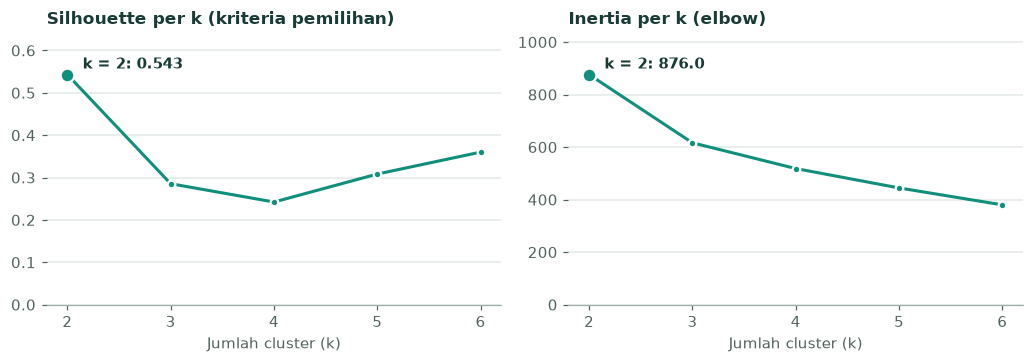

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for ax, column, title in ((axes[0], 'silhouette', 'Silhouette per k (kriteria pemilihan)'),
                          (axes[1], 'inertia', 'Inertia per k (elbow)')):
    ax.plot(candidates['k'], candidates[column], color=SERIES[0], linewidth=2, marker='o', markersize=5,
            markeredgecolor='white', markeredgewidth=1.5)
    chosen = candidates[candidates['terpilih']].iloc[0]
    ax.plot(chosen['k'], chosen[column], 'o', color=SERIES[0], markersize=9, markeredgecolor='white', markeredgewidth=1.5)
    ax.annotate(f"k = {int(chosen['k'])}: {chosen[column]:.3f}" if column == 'silhouette' else f"k = {int(chosen['k'])}: {chosen[column]:.1f}",
                (chosen['k'], chosen[column]), xytext=(10, 4), textcoords='offset points', fontweight='bold')
    ax.set_xticks(candidates['k'])
    ax.set_xlabel('Jumlah cluster (k)')
    ax.set_ylim(0, candidates[column].max() * 1.18)
    ax.grid(axis='x', visible=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 4. Perhitungan silhouette
Bagian ini menghitung ulang model terpilih dan menunjukkan rumusnya pada satu destinasi, Monumen Nasional.

Segmen diberi nomor berdasarkan harga rata-rata, dari yang terendah. Ini sama dengan penamaan pada `train_clusters`.

In [6]:
model = results[selected_k]
inertia, centroids, labels = model['inertia'], model['centers'], model['labels']
a, b, s, distances = silhouette_samples(X, labels)
silhouette_score = float(s.mean())

prices = destinations['price'].to_numpy(dtype=float)
order = sorted(range(selected_k), key=lambda j: prices[labels == j].mean())
segment_of = {cluster: index + 1 for index, cluster in enumerate(order)}
segments = np.array([segment_of[int(label)] for label in labels])
print('Silhouette rata-rata model:', round(silhouette_score, 5))

i = int(destinations.index[destinations['place_id'] == 1][0])
own = labels == labels[i]
other = ~own
center_distance = np.linalg.norm(X[i] - centroids, axis=1)
print('\nContoh:', destinations.loc[i, 'place_name'])
print('Fitur:', {c: round(float(v), 3) for c, v in zip(feature_columns, X[i])})
print('Jarak ke tiap pusat:', {f'Segmen {segment_of[j]}': round(float(d), 3) for j, d in enumerate(center_distance)})
print(f'Masuk Segmen {segments[i]} karena pusatnya paling dekat.')
print(f'a(i) = rata-rata jarak ke {own.sum() - 1} anggota lain = {distances[i, own].sum() / (own.sum() - 1):.3f}')
print(f'b(i) = rata-rata jarak ke {other.sum()} anggota segmen lain = {distances[i, other].mean():.3f}')
print(f's(i) = ({b[i]:.3f} - {a[i]:.3f}) / max({a[i]:.3f}, {b[i]:.3f}) = {s[i]:.3f}')

Silhouette rata-rata model: 0.54302

Contoh: Monumen Nasional
Fitur: {'c1_ticket_price_z': -0.046, 'c2_rating_z': 0.757, 'category_alam': 0.0, 'category_bahari': 0.0, 'category_belanja': 0.0, 'category_budaya': 1.0, 'category_hiburan': 0.0, 'category_religi': 0.0}
Jarak ke tiap pusat: {'Segmen 1': 1.135, 'Segmen 2': 3.614}
Masuk Segmen 1 karena pusatnya paling dekat.
a(i) = rata-rata jarak ke 413 anggota lain = 1.620
b(i) = rata-rata jarak ke 29 anggota segmen lain = 3.843
s(i) = (3.843 - 1.620) / max(1.620, 3.843) = 0.579


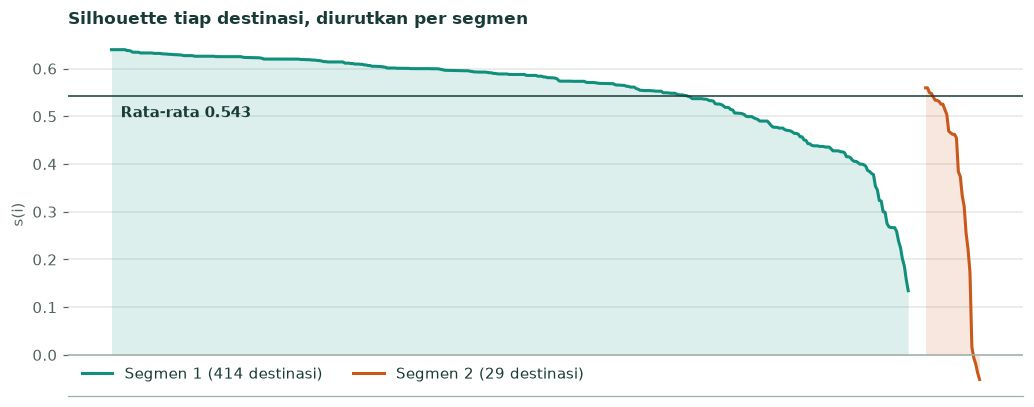

,segmen,anggota,rata_rata_s,terendah,tertinggi,negatif
0,1,414,0.555,0.135,0.64,0
1,2,29,0.369,-0.052,0.56,4


Lima destinasi dengan s(i) terendah:


,place_id,place_name,category_clean,price,segmen,a,b,s
174,175,Museum Ullen Sentalu,budaya,100000,2,2.841,2.694,-0.052
38,39,Museum Macan (Modern and Contemporary Art in N...,budaya,100000,2,2.540,2.443,-0.038
4,5,Atlantis Water Adventure,hiburan,94000,2,2.382,2.337,-0.019
409,410,Ciputra Waterpark,hiburan,95000,2,2.448,2.433,-0.006
248,249,Upside Down World Bandung,hiburan,100000,2,3.136,3.189,0.016


In [7]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
cursor = 0
for segment in sorted(set(segments.tolist())):
    values = np.sort(s[segments == segment])[::-1]
    x = np.arange(cursor, cursor + len(values))
    ax.fill_between(x, 0, values, color=SERIES[segment - 1], alpha=0.14, linewidth=0)
    ax.plot(x, values, color=SERIES[segment - 1], linewidth=2, label=f'Segmen {segment} ({len(values)} destinasi)')
    cursor += len(values) + 8
ax.axhline(0, color='#9fb0a8', linewidth=1)
ax.axhline(silhouette_score, color='#183b36', linewidth=1)
ax.annotate(f'Rata-rata {silhouette_score:.3f}', (0, silhouette_score), xytext=(6, -14), textcoords='offset points', fontweight='bold')
ax.set_xticks([])
ax.grid(axis='x', visible=False)
ax.set_ylabel('s(i)')
ax.set_title('Silhouette tiap destinasi, diurutkan per segmen')
ax.legend(loc='lower left', ncols=2)
plt.tight_layout()
plt.show()

summary = pd.DataFrame([{'segmen': seg, 'anggota': int((segments == seg).sum()), 'rata_rata_s': s[segments == seg].mean(),
                         'terendah': s[segments == seg].min(), 'tertinggi': s[segments == seg].max(),
                         'negatif': int((s[segments == seg] < 0).sum())} for seg in sorted(set(segments.tolist()))])
display(summary.round(3))

per_destination = destinations[['place_id', 'place_name', 'category_clean', 'price']].copy()
per_destination['segmen'] = segments
per_destination['a'], per_destination['b'], per_destination['s'] = a.round(3), b.round(3), s.round(3)
print('Lima destinasi dengan s(i) terendah:')
display(per_destination.sort_values('s').head(5))

Panduan umum membaca silhouette (Kaufman & Rousseeuw, 1990): 0,71–1 kuat; 0,51–0,70 wajar; 0,26–0,50 lemah; 0,25 ke bawah tidak substansial. Nilai ini mengukur bentuk cluster pada data latih, **bukan akurasi rekomendasi**.

## 5. Isi tiap segmen
Harga pada pusat dapat lebih rendah daripada harga asli rata-rata karena pusat dihitung dari harga yang sudah dibatasi P99.

In [8]:
ratings = destinations['c2_rating_for_model'].to_numpy(dtype=float)
price_values = np.minimum(prices, np.percentile(prices, 99))
price_mean, price_std = price_values.mean(), price_values.std()
segment_rows = []
for segment in sorted(set(segments.tolist())):
    members = segments == segment
    center = centroids[order[segment - 1]]
    segment_rows.append({'segmen': segment, 'anggota': int(members.sum()), 'porsi_%': round(100 * members.mean(), 1),
                         'harga_asli_rata_rata': round(prices[members].mean()),
                         'harga_pada_pusat': round(price_mean + center[0] * price_std),
                         'rating_rata_rata': round(ratings[members].mean(), 3),
                         'kategori_terbanyak': destinations.loc[members, 'category_clean'].mode()[0]})
display(pd.DataFrame(segment_rows))

centroid_table = pd.DataFrame(centroids[order].T, index=feature_columns,
                              columns=[f'Segmen {n + 1}' for n in range(selected_k)])
centroid_table['selisih'] = (centroid_table.iloc[:, 0] - centroid_table.iloc[:, -1]).abs()
display(centroid_table.round(3))
strongest = centroid_table['selisih'].idxmax()
print('Selisih pusat terbesar:', strongest, '=', round(float(centroid_table.loc[strongest, 'selisih']), 3))

,segmen,anggota,porsi_%,harga_asli_rata_rata,harga_pada_pusat,rating_rata_rata,kategori_terbanyak
0,1,414,93.5,11210,11210,4.443,hiburan
1,2,29,6.5,212552,178897,4.434,hiburan


,Segmen 1,Segmen 2,selisih
c1_ticket_price_z,-0.233,3.325,3.558
c2_rating_z,0.003,-0.040,0.043
category_alam,0.254,0.103,0.150
category_bahari,0.106,0.138,0.032
category_belanja,0.036,0.000,0.036
category_budaya,0.275,0.172,0.103
category_hiburan,0.287,0.586,0.299
category_religi,0.041,0.000,0.041


Selisih pusat terbesar: c1_ticket_price_z = 3.558


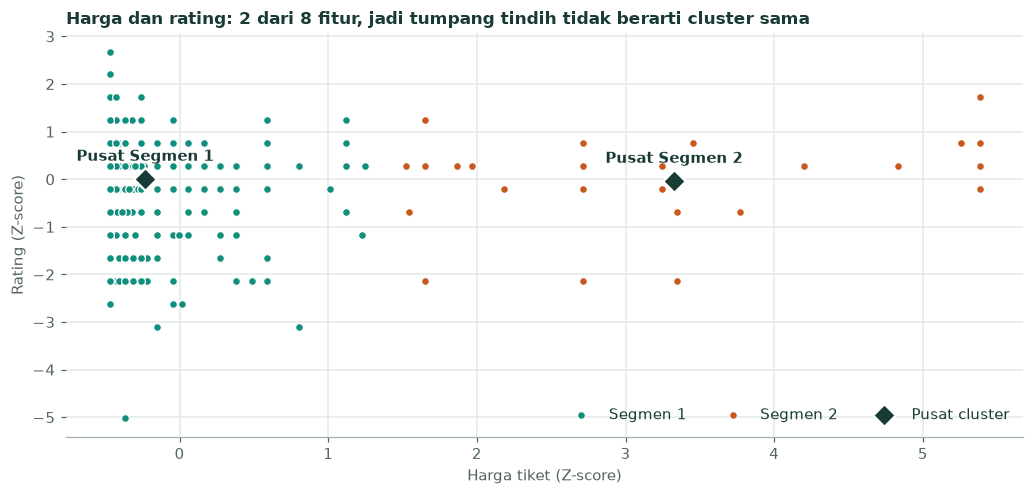

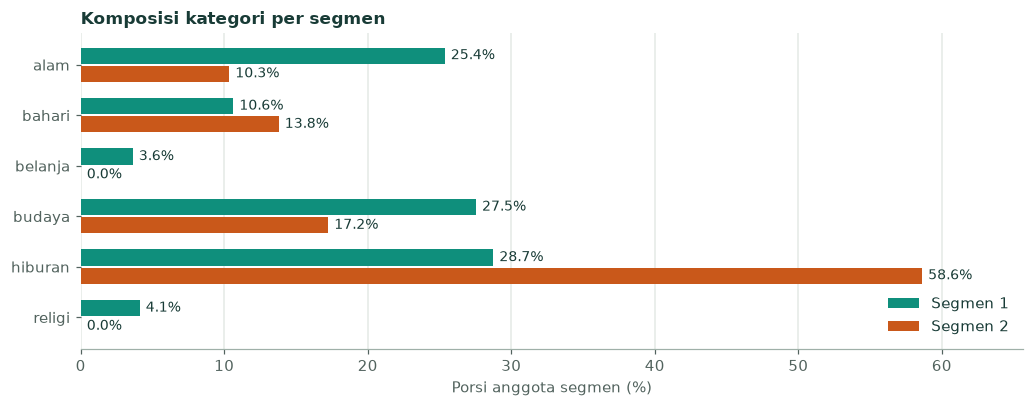

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for segment in sorted(set(segments.tolist())):
    members = segments == segment
    ax.scatter(X[members, 0], X[members, 1], s=26, color=SERIES[segment - 1], edgecolors='white', linewidths=0.8,
               label=f'Segmen {segment}', zorder=2)
ax.scatter(centroids[order, 0], centroids[order, 1], s=110, marker='D', color='#183b36', edgecolors='white',
           linewidths=1.5, label='Pusat cluster', zorder=3)
for index, cluster in enumerate(order):
    ax.annotate(f'Pusat Segmen {index + 1}', centroids[cluster, :2], xytext=(0, 12), textcoords='offset points',
                ha='center', fontweight='bold')
ax.set_xlabel('Harga tiket (Z-score)')
ax.set_ylabel('Rating (Z-score)')
ax.set_title('Harga dan rating: 2 dari 8 fitur, jadi tumpang tindih tidak berarti cluster sama')
ax.legend(loc='lower right', ncols=3)
plt.tight_layout()
plt.show()

category_columns = [c for c in feature_columns if c.startswith('category_')]
names = [c.replace('category_', '') for c in category_columns]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
height = 0.32
positions = np.arange(len(names))[::-1]
for index, cluster in enumerate(order):
    values = 100 * centroids[cluster, [feature_columns.index(c) for c in category_columns]]
    offset = height / 2 + 0.02 if index == 0 else -height / 2 - 0.02
    bars = ax.barh(positions + offset, values, height=height, color=SERIES[index], label=f'Segmen {index + 1}')
    ax.bar_label(bars, fmt='%.1f%%', padding=4, fontsize=9)
ax.set_yticks(positions, names)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Porsi anggota segmen (%)')
ax.set_title('Komposisi kategori per segmen')
ax.legend(loc='lower right')
ax.set_xlim(right=max(100 * centroids[:, [feature_columns.index(c) for c in category_columns]].max(), 1) * 1.12)
plt.tight_layout()
plt.show()

## 6. Metrik tambahan
- **TSS:** total kuadrat jarak ke rata-rata data, sebelum dikelompokkan.
- **BSS = TSS − inertia:** variasi yang dijelaskan pembagian cluster.
- **Calinski–Harabasz** $=\frac{BSS/(k-1)}{WSS/(n-k)}$: makin besar makin baik.
- **Davies–Bouldin:** rata-rata rasio sebaran cluster terhadap jarak antarpusat: makin kecil makin baik.

In [10]:
n, k = X.shape[0], selected_k
total_ss = float(((X - X.mean(axis=0)) ** 2).sum())
between_ss = total_ss - inertia
spread = [float(np.linalg.norm(X[labels == j] - centroids[j], axis=1).mean()) for j in range(k)]
davies_bouldin = float(np.mean([max((spread[i] + spread[j]) / np.linalg.norm(centroids[i] - centroids[j])
                                    for j in range(k) if j != i) for i in range(k)]))
calinski_harabasz = (between_ss / (k - 1)) / (inertia / (n - k))
metrics = pd.Series({'silhouette': silhouette_score, 'inertia (WSS)': inertia, 'TSS': total_ss, 'BSS': between_ss,
                     'variasi terjelaskan (%)': 100 * between_ss / total_ss, 'Calinski-Harabasz': calinski_harabasz,
                     'Davies-Bouldin': davies_bouldin}, name='nilai')
display(metrics.round(4).to_frame())

,nilai
silhouette,0.5430
inertia (WSS),876.0290
TSS,1222.5914
BSS,346.5624
variasi terjelaskan (%),28.3465
Calinski-Harabasz,174.4623
Davies-Bouldin,0.8226


## 7. Interpretasi
- **Pilihan k** mengikuti silhouette tertinggi pada kandidat yang memenuhi syarat ukuran. Inertia tetap turun pada setiap k, jadi tidak menunjukkan satu titik pilihan yang tegas.
- **Pemisahan segmen terutama didorong harga** (lihat selisih pusat pada bagian 5); rating kedua segmen hampir sama.
- **Variasi terjelaskan** menunjukkan seberapa banyak variasi data yang ditangkap pembagian ini. Bila kecil, segmen hanyalah ringkasan kasar, bukan pengelompokan minat wisata yang rinci.
- **Silhouette negatif** menandakan destinasi yang lebih dekat ke segmen lain.
- **Tidak ada data acuan,** sehingga semua metrik ini evaluasi internal dan bukan akurasi. Rating dan harga adalah snapshot sumber; rating Taman Hutan Raya Banten diisi median untuk pelatihan.

## 8. Bandingkan dengan laporan tersimpan
Notebook ini tidak menulis file. Untuk memperbarui label website dan laporan JSON, jalankan `manage.py preprocess_destinations`, `import_destinations`, lalu `train_clusters`.

In [11]:
report_file = PROJECT_ROOT / REPORT_PATH
if report_file.is_file():
    report = json.loads(report_file.read_text(encoding='utf-8'))
    stored_labels = [item['cluster_id'] for item in report['assignments']]
    checks = {'k': (selected_k, report['selected_k']),
              'silhouette': (round(silhouette_score, 5), report['silhouette']),
              'inertia': (round(inertia, 5), report['inertia'])}
    comparison = pd.DataFrame([{'ukuran': name, 'notebook': left, 'laporan': right, 'cocok': left == right}
                               for name, (left, right) in checks.items()])
    comparison.loc[len(comparison)] = ['label 443 destinasi', '-', '-', labels.tolist() == stored_labels]
    display(comparison)
    print('Semua cocok dengan laporan.' if comparison['cocok'].all() else 'Ada perbedaan: periksa versi data atau library.')
else:
    comparison = None
    print('Laporan belum ada; jalankan manage.py train_clusters untuk menyimpannya.')

,ukuran,notebook,laporan,cocok
0,k,2.0,2.0,True
1,silhouette,0.54302,0.54302,True
2,inertia,876.02902,876.02902,True
3,label 443 destinasi,-,-,True


Semua cocok dengan laporan.
